# 04 · EDA with sales data: what sells, and what does the author earn?

**Project:** Digital Publishing Opportunity Intelligence

**Author:** Stefan Radević · Data Science Bootcamp · Capstone project

## 1. TL;DR

**Key findings** from **55,690 books** with copies sold (synthetic example data) and **today's Kindle rules**

- **A few hits decide the market:** the median book sells about **78 copies a year**, while the top 1% hold **47.0%** of all copies.
- **One book rarely pays much:** the median author earns **94 dollars a year** self-published, **146** with a small and **473** with a large publisher.
- **Per copy, self-publishing pays most:** the author keeps **61–68%** of the price from 2.99 to 12.99 dollars, against about 21–24% with a small publisher and **17.5%** with a
  large one. A publisher must sell about **2.9** (small) or **3.5–3.9 times** (large) more copies to pay the author the same.
- **Without hits the niches change:** hits hold **45.3%** of author income. For less-known authors without hits, **Cookbooks**, **Health**, **Arts** and **Humor** lead, while
  Romance falls to 16th and Mystery to 17th place.

## 2. Introduction & motivation

In the first part of the project the data had no copies sold, so I could only study popularity through ratings. This notebook works with a data set
that also has the **number of copies sold**. The sales numbers are **synthetic**, made for this learning example. With copies sold, the project asks:

> **How many copies a year can a new Kindle book expect, from its niche, price, length, series, publishing route and the author's experience?**

and, as a sub-question:

> **How well does this work for less-known authors without hits, and which niches pay them most?**

- **Copies a year** is the number of copies a book sells in a full calendar year. Section 7 shows how I count it fairly for books of different ages.
- **Niche, price, length and series** describe the book draft. **Publishing route** is self-published, a small publisher or a large publisher, and the
  **author's experience** is how many books the author has published before. An author knows all of them before publishing.
- **Less-known authors** have at most 2 earlier books, and **hits** are the top 1% of books by copies a year. Section 9.6 shows both.
- The result is an **expected number of copies a year**. With the Kindle rules of section 9.3 it becomes the **author's income a year** for each route and price.

This notebook looks at the new data, explores what sells and what the author earns, and prepares one table for the models. The models are in the
`06.x` notebooks.

## 3. Data provenance

| Data | Source |
|---|---|
| Books: title, author, niche, price, pages, publisher, ratings | Amazon Reviews 2023, Kindle Store, cleaned in `01_eda.ipynb` |
| Share of reviews from verified buyers | Amazon Reviews 2023, Kindle Store reviews |
| **Copies sold per book and year, 2019–2022** | **synthetic** example data |
| Royalty rules | [KDP eBook Royalties](https://kdp.amazon.com/en_US/help/topic/G200644210), [KDP List Price Requirements](https://kdp.amazon.com/help/topic/G200634560), [KDP Digital Book Pricing](https://kdp.amazon.com/help/topic/G200634500), [Authors Guild](https://authorsguild.org/news/e-book-royalty-math-the-house-always-wins-2/) |

## 4. Data dictionary

**`kindle_books_sales.parquet`**: one row per book

| Column | Meaning |
|---|---|
| `parent_asin`, `title`, `author` | book ID, title, author |
| `niche` | the book's genre |
| `route` | self-published, small publisher (under 500 books in the catalog) or large publisher (500 or more) |
| `price` | list price in dollars |
| `pages`, `file_mb` | length; file size in MB |
| `published`, `publication_year` | publication date and year |
| `self_published`, `is_series` | 1 = yes, 0 = no |
| `author_earlier_books` | books the author published before this one |
| `rating_number` | Amazon ratings |
| `verified_share` | share of the book's reviews written by verified buyers |

**`kindle_sales_2019_2022.parquet`**: one row per book and year

| Column | Meaning |
|---|---|
| `parent_asin`, `year` | book and calendar year |
| `copies_sold` | copies sold in that year |

**Columns I create:** `copies_per_year`, `author_per_copy` (dollars for the author from one copy) and `author_income` (dollars a year).

## 5. Setup

The royalty rules are constants. `SMALL_ROYALTY` is my assumption: small presses pay from about 20% to 50% of what they receive
([Authors Guild](https://authorsguild.org/news/half-of-net-proceeds-is-the-fair-royalty-rate-for-e-books/), [Every](https://every.to/praxis/negotiating-your-contract-11294421)), and I use the middle.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
PROCESSED = PROJECT / "data" / "processed"

KDP_70_BAND = (2.99, 12.99)     # 70% KDP royalty on Amazon.com since July 2026
DELIVERY_PER_MB = 0.15          # delivery cost per MB under the 70% royalty
AGENCY_SHARE = 0.70             # what a large publisher receives from Amazon
LARGE_ROYALTY = 0.25            # author's share of what a large publisher receives
SMALL_ROYALTY = 0.35            # author's share of what a small publisher receives (assumption)
HIT_SHARE = 0.01                # the top 1% of books by copies are "hits"
LESS_KNOWN_MAX = 2              # less-known author: at most 2 earlier books
ROUTES = ["self-published", "small publisher", "large publisher"]
BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#c3c2b7", "#3a9a5b"
ROUTE_COLORS = dict(zip(ROUTES, [BLUE, GREEN, ORANGE]))
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})

books = pd.read_parquet(PROCESSED / "kindle_books_sales.parquet")
sales = pd.read_parquet(PROCESSED / "kindle_sales_2019_2022.parquet")
print("Books:", books.shape, "| sales:", sales.shape)

Books: (70361, 15) | sales: (183720, 3)


## 6. First look

The sales data is new for this project, so I look at both tables with `.head()`, `.info()` and `.describe()`.

In [2]:
books.head()

,parent_asin,title,author,niche,route,price,pages,file_mb,published,publication_year,self_published,is_series,author_earlier_books,rating_number,verified_share
0,B08NRPBGGR,Back To You,Bates,Literature & Fiction,small publisher,6.99,254.0,4.041992,2021-01-05,2021,0,0,0,38,0.545564
1,B07ZXPNJLL,Steele's War: A Damascus Steele nove...,Dietmar Wehr,Science Fiction & Fantasy,small publisher,3.99,365.0,1.104492,2019-11-02,2019,0,1,27,97,0.375000
2,B07NDJLVQR,'Charlotte's Search' Box Set Two: A ...,Simone Leigh,Literature & Fiction,small publisher,3.99,454.0,3.723633,2019-02-04,2019,0,1,67,105,0.000000
3,B07FBZ2QJZ,Baking at République: Masterful Tech...,Margarita Manzke,"Cookbooks, Food & Wine",small publisher,9.99,266.0,132.867188,2019-04-02,2019,0,0,0,308,0.625000
4,B09J1RS1TC,The Secret Of St. Christopher's Girl...,David Crowley,"Mystery, Thriller & Suspense",small publisher,9.99,247.0,0.547852,2021-10-08,2021,0,0,0,48,0.601462


In [3]:
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 70361 entries, 0 to 70360
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   parent_asin           70361 non-null  str           
 1   title                 70361 non-null  str           
 2   author                70282 non-null  str           
 3   niche                 70361 non-null  str           
 4   route                 70361 non-null  str           
 5   price                 70361 non-null  float64       
 6   pages                 66887 non-null  float64       
 7   file_mb               70361 non-null  float64       
 8   published             70361 non-null  datetime64[ms]
 9   publication_year      70361 non-null  int32         
 10  self_published        70361 non-null  int64         
 11  is_series             70361 non-null  int64         
 12  author_earlier_books  70361 non-null  int64         
 13  rating_number         70361

In [4]:
display(sales.head(8))
sales.info()

,parent_asin,year,copies_sold
0,B08NRPBGGR,2021,183
1,B08NRPBGGR,2022,56
2,B07ZXPNJLL,2019,178
3,B07ZXPNJLL,2020,58
4,B07ZXPNJLL,2021,0
5,B07ZXPNJLL,2022,0
6,B07NDJLVQR,2019,768
7,B07NDJLVQR,2020,0


<class 'pandas.DataFrame'>
RangeIndex: 183720 entries, 0 to 183719
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   parent_asin  183720 non-null  str  
 1   year         183720 non-null  int64
 2   copies_sold  183720 non-null  int64
dtypes: int64(2), str(1)
memory usage: 6.0 MB


In [5]:
sales.groupby("year")["copies_sold"].describe(percentiles=[0.5, 0.9, 0.99]).round(1)

,count,mean,std,min,50%,90%,99%,max
year,,,,,,,,
2019,19155.0,1171.9,7078.7,0.0,72.0,2040.2,18475.1,535846.0
2020,38514.0,1017.7,9526.1,0.0,28.0,1340.0,15956.4,712015.0
2021,55690.0,683.3,5816.0,0.0,4.0,891.0,11195.2,446168.0
2022,70361.0,619.6,14088.9,0.0,0.0,595.0,9525.4,3210532.0


- The book table has **70,361** books and the sales table **183,720** rows, one for each book and year. Only `author` (79) and `pages` (3,474) have empty values.
- `copies_sold` is a whole number. The median per book and year falls from **72** in 2019 to **0** in 2022, because every year adds newer books, and many books sell nothing in
  some years.
- A few book-years are very large: the top 1% start at about **9,500–18,500** copies, and the largest is **3.2 million**.

## 7. Data quality audit

I check for missing values, duplicates, impossible values and sales before a book was published.

In [6]:
print("Missing values in books:")
print(books.isna().sum()[lambda s: s > 0])
print("\nMissing values in sales:", int(sales.isna().sum().sum()))
print("Duplicate books:", int(books["parent_asin"].duplicated().sum()), "| duplicate book-years:", int(sales.duplicated(["parent_asin", "year"]).sum()))
print("Negative copies:", int((sales["copies_sold"] < 0).sum()))
check = sales.merge(books[["parent_asin", "publication_year"]], on="parent_asin")
print("Sales before the year of publication:", int((check["year"] < check["publication_year"]).sum()))
print("Books without sales rows:", int((~books["parent_asin"].isin(sales["parent_asin"])).sum()))

Missing values in books:
author      79
pages     3474
dtype: int64

Missing values in sales: 0
Duplicate books: 0 | duplicate book-years: 0
Negative copies: 0
Sales before the year of publication: 0


Books without sales rows: 0


- **No duplicates**, **no negative copies**, **no sales before publication**, and every book has sales rows.
- `pages` is empty for 3,474 books and `author` for 79. I keep these books: `pages` is used only in the correlation, which skips empty values.

A book published in 2022 had less than one year to sell, and a book from 2019 had four. To compare books fairly I calculate **copies per year**.

**Rule.** `copies_per_year` = copies sold in 2019–2022 ÷ years on Amazon until 31 December 2022. Books published in 2022 had less than a full year, so I
leave them out of the yearly comparisons.

In [7]:
per_book = sales.groupby("parent_asin")["copies_sold"].sum().rename("copies_2019_2022")
books = books.merge(per_book, left_on="parent_asin", right_index=True)
books["years_on_amazon"] = (pd.Timestamp("2022-12-31") - pd.to_datetime(books["published"])).dt.days / 365.25
print(f"Books published in 2022 (left out): {(books['publication_year'] == 2022).sum():,}")
data = books[books["publication_year"] <= 2021].copy()
data["copies_per_year"] = data["copies_2019_2022"] / data["years_on_amazon"]
print(f"Books for the yearly comparisons: {len(data):,}")
data["copies_per_year"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1)

Books published in 2022 (left out): 14,671
Books for the yearly comparisons: 55,690


count      55690.0
mean         973.3
std        13411.0
min            0.0
25%           18.1
50%           78.3
75%          364.8
90%         1430.1
99%        13928.3
max      2803288.9
Name: copies_per_year, dtype: float64

- **14,671** books from 2022 are left out, so **55,690** books remain.
- The median book sells **78 copies a year**. A quarter sell **18 or fewer**, a quarter **365 or more**, the top 10% at least **1,430** and the top 1% at least **13,928**.

## 8. Univariate exploration

### 8.1 Copies sold per year

Sales are very uneven, so I use a **log scale** (each step is 10 times more).

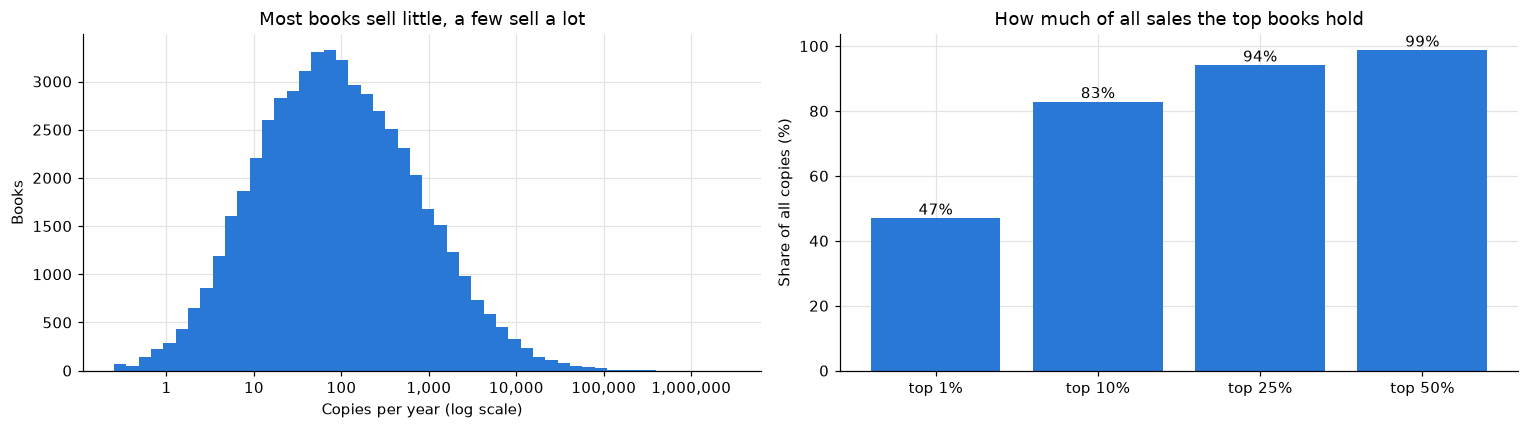

Books with 0 copies a year: 2.2%


,share of all copies %
top 1%,47.0
top 10%,82.8
top 25%,94.1
top 50%,98.7


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
values = data["copies_per_year"]
axes[0].hist(np.log10(values[values > 0]), bins=50, color=BLUE)
axes[0].set_xticks(range(0, 7), [f"{10 ** i:,}" for i in range(0, 7)])
axes[0].set_xlabel("Copies per year (log scale)")
axes[0].set_ylabel("Books")
axes[0].set_title("Most books sell little, a few sell a lot")
ordered = values.sort_values(ascending=False).to_numpy()
top_shares = pd.Series({f"top {p}%": ordered[: round(len(ordered) * p / 100)].sum() / ordered.sum() * 100 for p in [1, 10, 25, 50]})
bars = axes[1].bar(top_shares.index, top_shares.values, color=BLUE)
axes[1].bar_label(bars, fmt="%.0f%%")
axes[1].set_ylabel("Share of all copies (%)")
axes[1].set_title("How much of all sales the top books hold")
plt.tight_layout()
plt.show()
print(f"Books with 0 copies a year: {(values == 0).mean():.1%}")
top_shares.round(1).to_frame("share of all copies %")

- On the log scale the books spread from 1 to over a million copies a year.
- The **top 1%** of books hold **47.0%** of all copies, the top 10% hold **82.8%**, and the top 25% hold **94.1%**. Only **2.2%** of the books sell nothing.
- A few hits decide the market. This is why I use the **median** for a typical book.

### 8.2 Sales by year, route and price

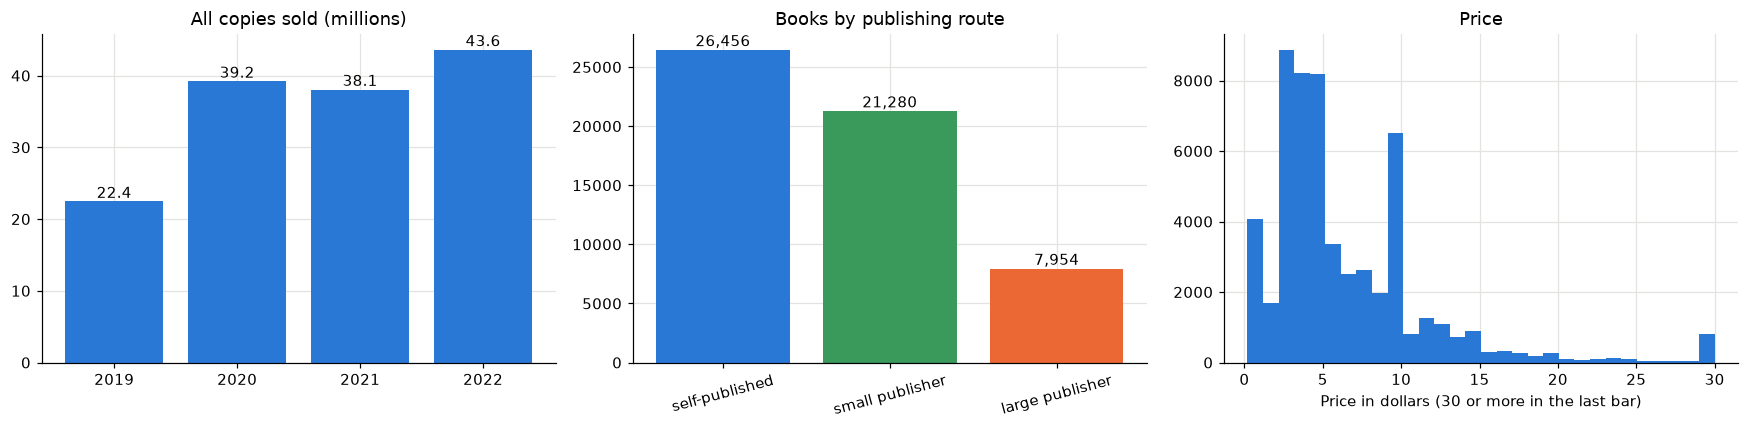

,count,25%,50%,75%
route,,,,
self-published,26456.0,2.99,3.99,5.99
small publisher,21280.0,3.99,5.75,9.99
large publisher,7954.0,4.99,9.59,12.99


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
by_year = sales.groupby("year")["copies_sold"].sum() / 1e6
bars = axes[0].bar(by_year.index.astype(str), by_year.values, color=BLUE)
axes[0].bar_label(bars, fmt="%.1f")
axes[0].set_title("All copies sold (millions)")
routes = data["route"].value_counts().loc[ROUTES]
bars = axes[1].bar(routes.index, routes.values, color=[ROUTE_COLORS[r] for r in routes.index])
axes[1].bar_label(bars, fmt="{:,.0f}")
axes[1].set_title("Books by publishing route")
axes[1].tick_params(axis="x", rotation=15)
axes[2].hist(data["price"].clip(upper=30), bins=30, color=BLUE)
axes[2].set_xlabel("Price in dollars (30 or more in the last bar)")
axes[2].set_title("Price")
plt.tight_layout()
plt.show()
data.groupby("route")["price"].describe()[["count", "25%", "50%", "75%"]].loc[ROUTES].round(2)

- All copies grow from about **22 million** in 2019 to about **44 million** in 2022, as more books from the sample are on sale.
- **26,456** books are self-published, **21,280** have a small and **7,954** a large publisher.
- Self-published books are the cheapest (median **3.99 dollars**), small publishers in the middle (**5.75**) and large publishers the most expensive (**9.59**).

## 9. Bivariate exploration

### 9.1 Which books sell more?

I compare the **median** copies per year, because a few hits pull the mean far up.

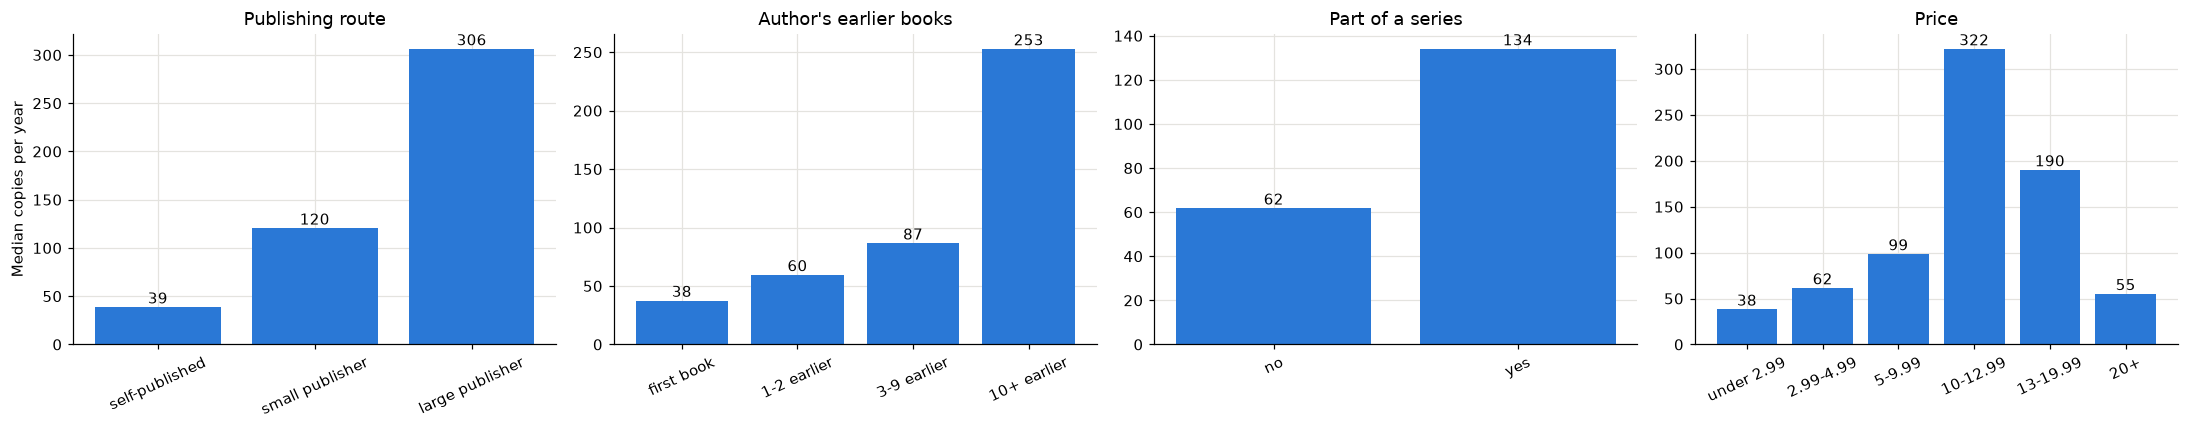

,books,median,mean
niche,,,
"Cookbooks, Food & Wine",651,205.4,1512.8
Romance,5955,147.1,792.3
"Mystery, Thriller & Suspense",3224,118.1,1850.0
Religion & Spirituality,3154,107.3,683.2
Arts & Photography,812,107.2,765.0
Business & Money,2770,58.4,461.5
Reference,365,56.9,586.7
Science Fiction & Fantasy,4308,51.4,560.1
Children's eBooks,3873,44.7,639.9


In [10]:
data["price_group"] = pd.cut(data["price"], [0, 2.98, 4.99, 9.99, 12.99, 19.99, np.inf],
                             labels=["under 2.99", "2.99-4.99", "5-9.99", "10-12.99", "13-19.99", "20+"])
data["experience"] = pd.cut(data["author_earlier_books"], [-1, 0, 2, 9, np.inf], labels=["first book", "1-2 earlier", "3-9 earlier", "10+ earlier"])
data["series"] = data["is_series"].map({0: "no", 1: "yes"})
panels = [("route", "Publishing route"), ("experience", "Author's earlier books"), ("series", "Part of a series"), ("price_group", "Price")]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (column, title) in zip(axes, panels):
    medians = data.groupby(column, observed=True)["copies_per_year"].median()
    if column == "route":
        medians = medians.loc[ROUTES]
    bars = ax.bar(medians.index.astype(str), medians.values, color=BLUE)
    ax.bar_label(bars, fmt="%.0f")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25)
axes[0].set_ylabel("Median copies per year")
plt.tight_layout()
plt.show()

niche_copies = data.groupby("niche")["copies_per_year"].agg(books="size", median="median", mean="mean")
niche_copies = niche_copies[niche_copies["books"] >= 300].sort_values("median", ascending=False)
pd.concat([niche_copies.head(5), niche_copies.tail(5)]).round(1)

- **Route:** the median book sells **39** copies a year when self-published, **120** with a small and **306** with a large publisher.
- **Experience:** **38** copies for a first book, **253** for an author with 10+ earlier books.
- **Series:** **134** copies against **62**.
- **Price:** the most at **10–12.99 dollars (322)**; the least under 2.99 (38) and above 20 (55). Many expensive books are publisher books.
- **Niches:** **Cookbooks, Food & Wine** (median **205**), **Romance** (147) and **Mystery** (118) sell most; **Education & Teaching** (31), **Children's eBooks** (45) and
  **Science Fiction & Fantasy** (51) least.

### 9.2 Correlation

How are copies sold related to the other numbers? Copies, price and earlier books are very uneven, so I use their logarithms.

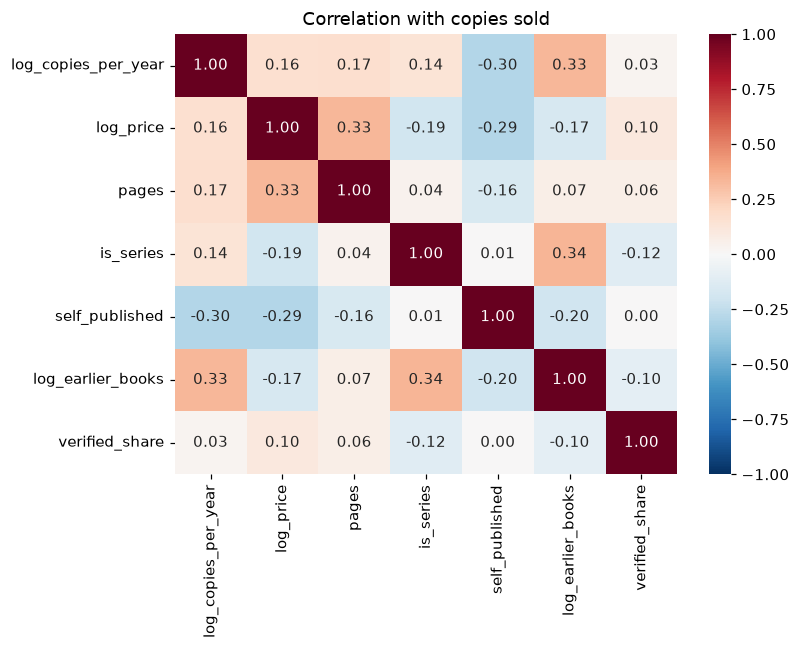

In [11]:
corr_data = pd.DataFrame({"log_copies_per_year": np.log1p(data["copies_per_year"]), "log_price": np.log1p(data["price"]),
                          "pages": data["pages"], "is_series": data["is_series"], "self_published": data["self_published"],
                          "log_earlier_books": np.log1p(data["author_earlier_books"]), "verified_share": data["verified_share"]})
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr_data.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Correlation with copies sold")
plt.tight_layout()
plt.show()

- Copies sold go most with the **author's earlier books** (**0.33**) and against **self-publishing** (**−0.30**).
- Pages (0.17), price (0.16) and series (0.14) add less. The share of verified buyers is unrelated (0.03).
- No two features are strongly related to each other (highest 0.34, series and earlier books).

### 9.3 How the price is divided: Kindle rules 2026

| Route | What Amazon pays | What the author receives |
|---|---|---|
| **Self-published** | 70% of (price − delivery) from 2.99 to 12.99 dollars, otherwise 35% of the price | everything Amazon pays |
| **Small publisher** | the same, paid to the publisher | 35% of what the publisher receives |
| **Large publisher** | 70% of the price | 25% of what the publisher receives = 17.5% of the price |

`split_price` returns the dollars of the author, the publisher and Amazon for one copy.

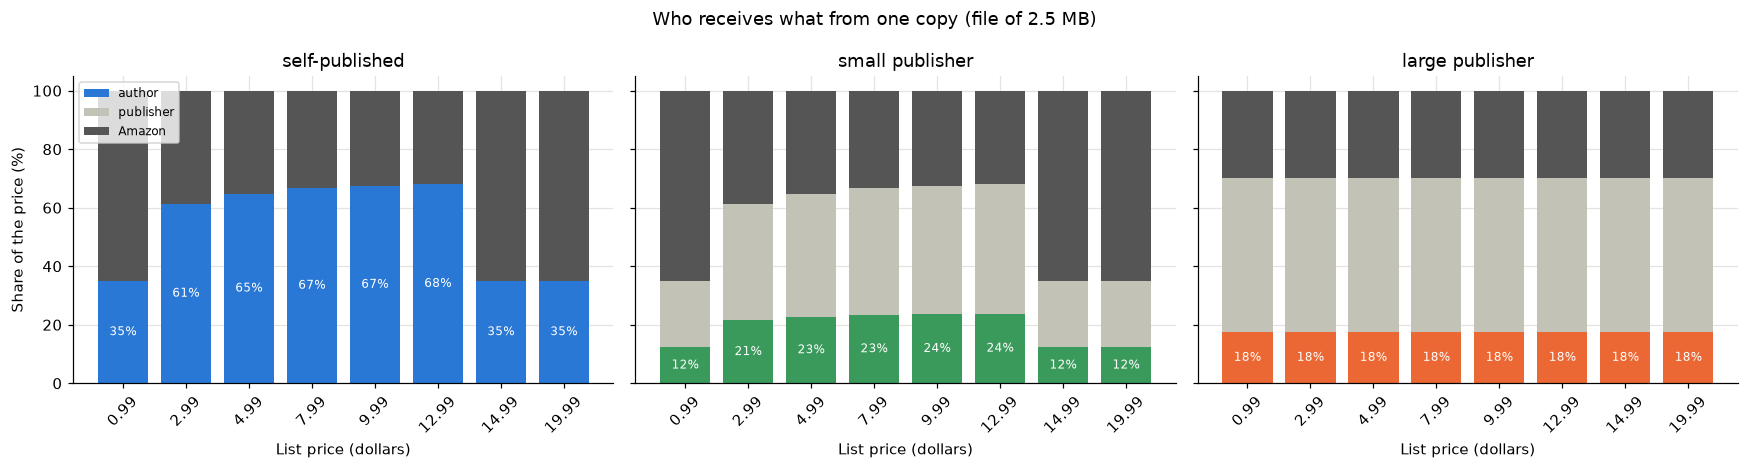

route,self-published,small publisher,large publisher
price,,,
0.99,0.35,0.12,0.17
2.99,1.83,0.64,0.52
4.99,3.23,1.13,0.87
7.99,5.33,1.87,1.40
9.99,6.73,2.36,1.75
12.99,8.83,3.09,2.27
14.99,5.25,1.84,2.62
19.99,7.00,2.45,3.50


In [12]:
def kdp_royalty(price, file_mb):
    price, file_mb = np.asarray(price, dtype=float), np.asarray(file_mb, dtype=float)
    in_band = (price >= KDP_70_BAND[0]) & (price <= KDP_70_BAND[1])
    return np.where(in_band, np.maximum(0.35 * price, 0.70 * (price - DELIVERY_PER_MB * file_mb)), 0.35 * price)


def split_price(price, file_mb, route):
    price = np.asarray(price, dtype=float)
    if route == "self-published":
        author, publisher = kdp_royalty(price, file_mb), np.zeros_like(price)
    elif route == "small publisher":
        received = kdp_royalty(price, file_mb)
        author, publisher = SMALL_ROYALTY * received, (1 - SMALL_ROYALTY) * received
    else:
        received = AGENCY_SHARE * price
        author, publisher = LARGE_ROYALTY * received, (1 - LARGE_ROYALTY) * received
    return author, publisher, price - author - publisher


MEDIAN_MB = books["file_mb"].median()
prices = np.array([0.99, 2.99, 4.99, 7.99, 9.99, 12.99, 14.99, 19.99])
rows = []
for route in ROUTES:
    author, publisher, amazon = split_price(prices, MEDIAN_MB, route)
    for p, a, pub, amz in zip(prices, author, publisher, amazon):
        rows.append({"route": route, "price": p, "author $": a, "author %": a / p * 100, "publisher %": pub / p * 100, "Amazon %": amz / p * 100})
split = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, route in zip(axes, ROUTES):
    part = split[split["route"] == route]
    labels = [f"{p:.2f}" for p in part["price"]]
    bottom = np.zeros(len(part))
    for column, color in [("author %", ROUTE_COLORS[route]), ("publisher %", GREY), ("Amazon %", "#555555")]:
        ax.bar(labels, part[column], bottom=bottom, color=color, label=column.replace(" %", ""))
        bottom += part[column].to_numpy()
    ax.bar_label(ax.containers[0], fmt="%.0f%%", label_type="center", color="white", fontsize=8)
    ax.set_title(route)
    ax.set_xlabel("List price (dollars)")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Share of the price (%)")
axes[0].legend(loc="upper left", fontsize=8)
plt.suptitle(f"Who receives what from one copy (file of {MEDIAN_MB:.1f} MB)")
plt.tight_layout()
plt.show()
split.pivot(index="price", columns="route", values="author $")[ROUTES].round(2)

- **Self-published:** the author keeps **35%** under 2.99 dollars, **61–68%** from 2.99 to 12.99 dollars, and **35%** again above 12.99. At 12.99 dollars this is **8.83 dollars** per
  copy; at 14.99 only **5.25**.
- **Small publisher:** about **21–24%** of the price in the 70% band (**1.13 dollars** at 4.99), and about **12%** outside it.
- **Large publisher:** **17.5%** at every price (**0.87 dollars** at 4.99); the publisher keeps 52.5% and Amazon 30%.
- **Amazon** keeps about 32–39% of the price of KDP books in the 70% band and **65%** outside it.

### 9.4 Author's income by route

Now I combine copies and rules: `author_income` = copies per year × `author_per_copy` for the book's own route.

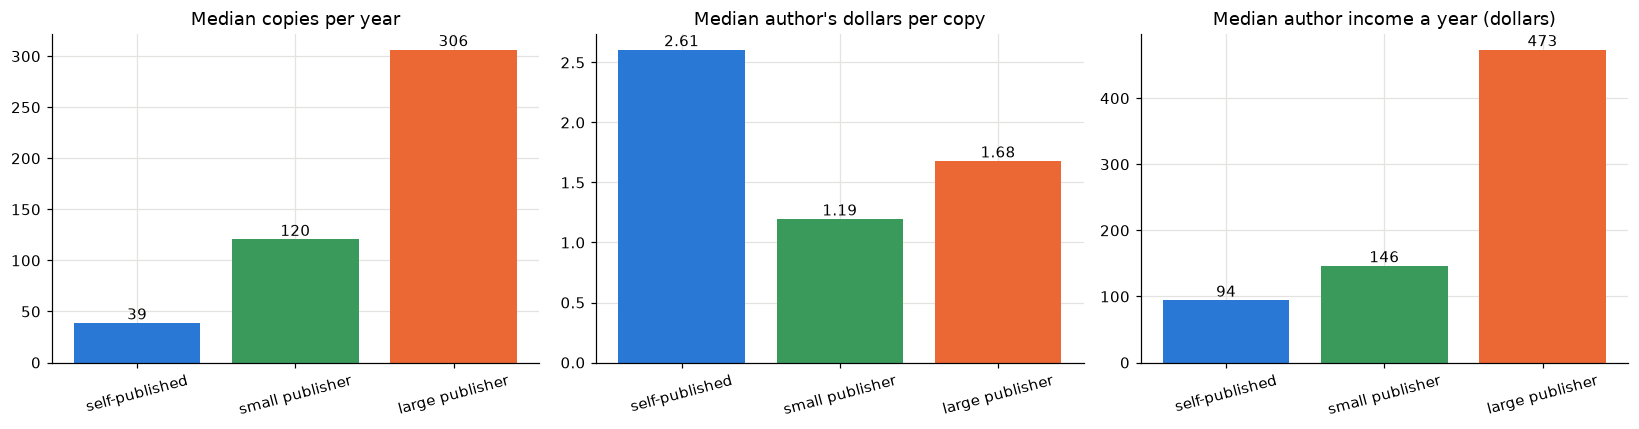

,books,median_copies,median_per_copy,median_income,mean_income,top_10pct_from
route,,,,,,
self-published,26456,38.6,2.6,94.1,1019.2,1702.5
small publisher,21280,120.5,1.2,146.3,1613.8,2448.7
large publisher,7954,306.2,1.7,473.2,5281.6,7432.6


In [13]:
for route in ROUTES:
    data["per_copy__" + route] = split_price(data["price"], data["file_mb"], route)[0]
data["author_per_copy"] = [data.at[i, "per_copy__" + r] for i, r in zip(data.index, data["route"])]
data["author_income"] = data["copies_per_year"] * data["author_per_copy"]

own = data.groupby("route").agg(books=("price", "size"), median_copies=("copies_per_year", "median"),
                                median_per_copy=("author_per_copy", "median"), median_income=("author_income", "median"),
                                mean_income=("author_income", "mean"), top_10pct_from=("author_income", lambda s: s.quantile(0.9))).loc[ROUTES]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title in [(axes[0], "median_copies", "Median copies per year"), (axes[1], "median_per_copy", "Median author's dollars per copy"),
                          (axes[2], "median_income", "Median author income a year (dollars)")]:
    bars = ax.bar(own.index, own[column], color=[ROUTE_COLORS[r] for r in own.index])
    ax.bar_label(bars, fmt="%.2f" if "per_copy" in column else "%.0f")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()
own.round(1)

- **Self-published:** **38.6** copies a year × **2.60 dollars** per copy = a median of **94 dollars a year**.
- **Small publisher:** **120.5** × **1.20** = **146 dollars**. **Large publisher:** **306.2** × **1.70** = **473 dollars**.
- The means are much higher (**1,019**, **1,614** and **5,282 dollars**), and the top 10% start at **1,703**, **2,449** and **7,433 dollars**. A few books earn most of the money.

Publishers sell more copies, but they also have different books. To compare only the **rules**, I take the self-published books and calculate
their income with the same copies and price under the other routes. The **break-even** is how many times more copies a publisher must sell to pay the
author the same.

In [14]:
self_books = data[data["route"] == "self-published"]
same_book = pd.DataFrame({route: self_books["copies_per_year"] * self_books["per_copy__" + route] for route in ROUTES})
same_table = same_book.agg(["median", "mean"]).T
same_table["share of self-published income"] = same_table["mean"] / same_table.loc["self-published", "mean"]
break_even = split.pivot(index="price", columns="route", values="author $")
break_even["small must sell x more"] = break_even["self-published"] / break_even["small publisher"]
break_even["large must sell x more"] = break_even["self-published"] / break_even["large publisher"]
observed = data.groupby("route")["copies_per_year"].median()
print(f"Large-publisher books sell {observed['large publisher'] / observed['self-published']:.1f}x and small-publisher books "
      f"{observed['small publisher'] / observed['self-published']:.1f}x the median copies of self-published books")
display(same_table.round(2))
break_even[["small must sell x more", "large must sell x more"]].round(1)

Large-publisher books sell 7.9x and small-publisher books 3.1x the median copies of self-published books


,median,mean,share of self-published income
self-published,94.14,1019.17,1.00
small publisher,32.95,356.71,0.35
large publisher,28.93,298.73,0.29


route,small must sell x more,large must sell x more
price,,
0.99,2.9,2.0
2.99,2.9,3.5
4.99,2.9,3.7
7.99,2.9,3.8
9.99,2.9,3.9
12.99,2.9,3.9
14.99,2.9,2.0
19.99,2.9,2.0


- **Same book, same sales:** self-published books would earn only **35%** of their income with a small publisher and **29%** with a large one.
- **Break-even:** a small publisher must sell **2.9 times** more copies; a large one **3.5–3.9 times** more in the 70% band, and **2.0 times** more under 2.99 or above 12.99 dollars.
- **Observed:** large-publisher books sell **7.9 times** and small-publisher books **3.1 times** the median of self-published books. These are different books with more readers.
- For an author the question is: **will this publisher really sell at least 3–4 times more copies of my book?**

### 9.5 Which price pays the author best?

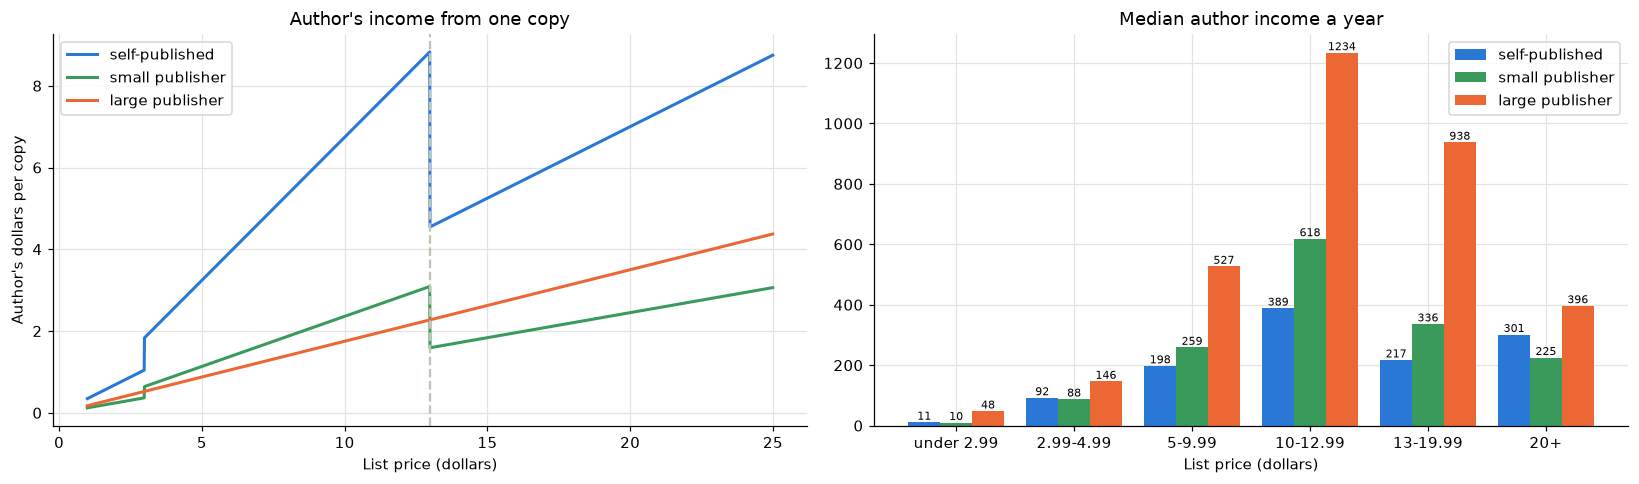

books  median_copies  median_income
route           price_group                                     
large publisher under 2.99     356          190.4           47.9
                2.99-4.99     1657          196.0          146.3
                5-9.99        2952          376.6          527.0
                10-12.99      1326          598.5         1233.8
                13-19.99      1122          362.8          937.6
                20+            541           69.2          396.5
self-published  under 2.99    3526           25.3           11.0
                2.99-4.99    14779           41.5           92.2
                5-9.99        7228           39.9          197.7
                10-12.99       259           57.0          388.6
                13-19.99       389           39.2          217.2
                20+            275           23.7          301.3
small publisher under 2.99    2037           67.2           10.0
                2.99-4.99     8426          101.7           87.6
                5-9.99        7052          145.1          258.9
                10-12.99      1601          259.3          618.2
                13-19.99      1462          169.1          336.2
                20+            702           56.4          225.3

In [15]:
price_line = np.arange(0.99, 25.0, 0.01)
by_price = data.groupby(["route", "price_group"], observed=True).agg(books=("price", "size"), median_copies=("copies_per_year", "median"),
                                                                   median_income=("author_income", "median"))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for route in ROUTES:
    axes[0].plot(price_line, split_price(price_line, MEDIAN_MB, route)[0], color=ROUTE_COLORS[route], linewidth=2, label=route)
axes[0].axvline(KDP_70_BAND[1], color=GREY, linestyle="--")
axes[0].set_xlabel("List price (dollars)")
axes[0].set_ylabel("Author's dollars per copy")
axes[0].set_title("Author's income from one copy")
axes[0].legend()
chart = by_price["median_income"].unstack(0)[ROUTES]
x = np.arange(len(chart))
for k, route in enumerate(ROUTES):
    bars = axes[1].bar(x + (k - 1) * 0.27, chart[route], width=0.27, color=ROUTE_COLORS[route], label=route)
    axes[1].bar_label(bars, fmt="%.0f", fontsize=7)
axes[1].set_xticks(x, chart.index)
axes[1].set_xlabel("List price (dollars)")
axes[1].set_title("Median author income a year")
axes[1].legend()
plt.tight_layout()
plt.show()
by_price.round(1)

- Per copy, a self-published author earns most at **12.99 dollars (8.83)**, and much less just above it.
- **Self-published books:** the median income rises from **11 dollars** under 2.99 to **92** at 2.99–4.99, **198** at 5–9.99 and **389** at 10–12.99, while the copies stay
  similar (about **40–57** a year). Only **259** self-published books cost 10–12.99 dollars.
- Publishers also earn most at **10–12.99 dollars** (small **618**, large **1,234**). **Under 2.99** is the weakest price for every route.

### 9.6 Niches without the biggest hits

A few books sell very many copies. They may make a niche look better than it is for a typical or less-known author.

**Rule.** A book is a **hit** if it is in the top 1% of copies per year. An author is **less known** if they had at most 2 earlier books. I compare
every niche in three groups: all books, books without hits, and books by less-known authors without hits.

Hits: 557 books with at least 13,928 copies a year
Hits hold 45.3% of all author income
Less-known authors: 52.8% of the books


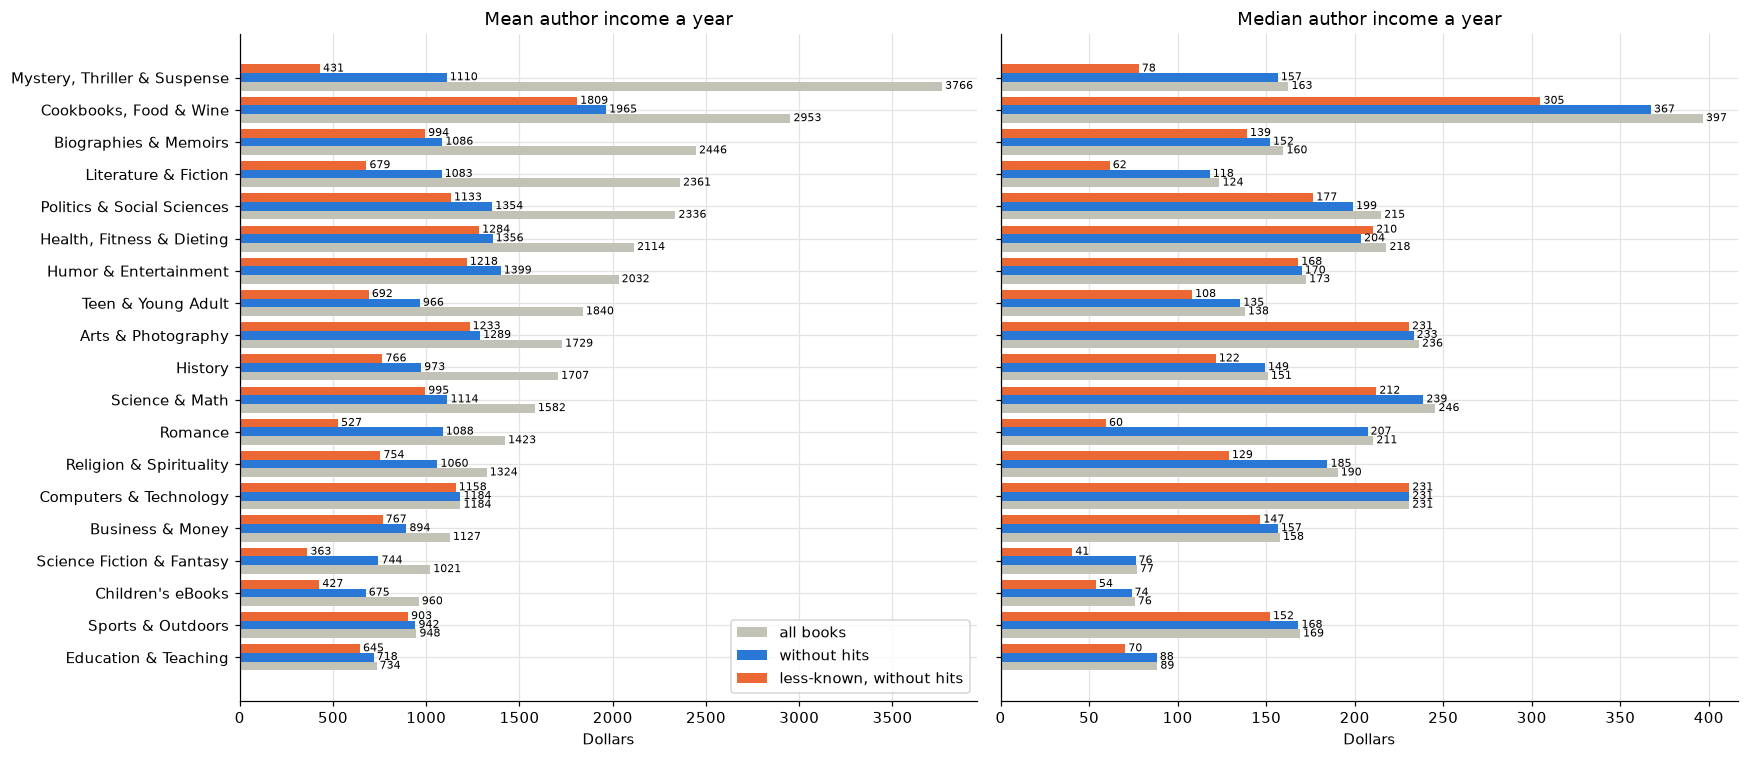

all books              without hits              less-known, without hits             
                                 books median  mean        books median  mean                    books median  mean
niche                                                                                                              
Cookbooks, Food & Wine             651    397  2953          638    367  1965                      488    305  1809
Health, Fitness & Dieting          754    218  2114          743    204  1356                      613    210  1284
Arts & Photography                 812    236  1729          808    233  1289                      593    231  1233
Humor & Entertainment              505    173  2032          501    170  1399                      351    168  1218
Computers & Technology             757    231  1184          757    231  1184                      603    231  1158
Politics & Social Sciences        1243    215  2336         1221    199  1354                      967    177  1133
Science & Math                     518    246  1582          513    239  1114                      408    212   995
Biographies & Memoirs             1848    160  2446         1820    152  1086                     1523    139   994
Sports & Outdoors                  515    169   948          514    168   942                      420    152   903
Business & Money                  2770    158  1127         2761    157   894                     2232    147   767
History                           1606    151  1707         1597    149   973                     1137    122   766
Religion & Spirituality           3154    190  1324         3140    185  1060                     1766    129   754
Teen & Young Adult                2334    138  1840         2308    135   966                     1192    108   692
Literature & Fiction             17648    124  2361        17375    118  1083                     7740     62   679
Education & Teaching               949     89   734          948     88   718                      742     70   645
Romance                           5955    211  1423         5914    207  1088                     1122     60   527
Mystery, Thriller & Suspense      3224    163  3766         3188    157  1110                     1193     78   431
Children's eBooks                 3873     76   960         3838     74   675                     2621     54   427
Science Fiction & Fantasy         4308     77  1021         4290     76   744                     1753     41   363

,all books,without hits,"less-known, without hits",hits' share of income %
niche,,,,
"Cookbooks, Food & Wine",2,1,1,34.8
"Health, Fitness & Dieting",6,3,2,36.8
Arts & Photography,9,5,3,25.8
Humor & Entertainment,7,2,4,31.7
Computers & Technology,14,6,5,0.0
Politics & Social Sciences,5,4,6,43.1
Science & Math,11,7,7,30.3
Biographies & Memoirs,3,10,8,56.3
Sports & Outdoors,18,15,9,0.7


In [16]:
hit_limit = data["copies_per_year"].quantile(1 - HIT_SHARE)
data["hit"] = data["copies_per_year"] >= hit_limit
data["less_known"] = data["author_earlier_books"] <= LESS_KNOWN_MAX
print(f"Hits: {data['hit'].sum():,} books with at least {hit_limit:,.0f} copies a year")
print(f"Hits hold {data.loc[data['hit'], 'author_income'].sum() / data['author_income'].sum():.1%} of all author income")
print(f"Less-known authors: {data['less_known'].mean():.1%} of the books")

groups = {"all books": data, "without hits": data[~data["hit"]], "less-known, without hits": data[~data["hit"] & data["less_known"]]}
niche_table = pd.concat({name: part.groupby("niche")["author_income"].agg(books="size", median="median", mean="mean")
                         for name, part in groups.items()}, axis=1)
big_niches = data["niche"].value_counts().loc[lambda s: s >= 500].index
niche_table = niche_table.loc[big_niches].sort_values(("all books", "mean"))
hit_share = data.groupby("niche").apply(lambda d: d.loc[d["hit"], "author_income"].sum() / d["author_income"].sum() * 100)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
y = np.arange(len(niche_table))
for ax, statistic, title in [(axes[0], "mean", "Mean author income a year"), (axes[1], "median", "Median author income a year")]:
    for k, (name, color) in enumerate(zip(groups, [GREY, BLUE, ORANGE])):
        bars = ax.barh(y + (k - 1) * 0.27, niche_table[(name, statistic)], height=0.27, color=color, label=name)
        ax.bar_label(bars, fmt="%.0f", fontsize=7, padding=2)
    ax.set_title(title)
    ax.set_xlabel("Dollars")
axes[0].set_yticks(y, niche_table.index)
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

display(niche_table.sort_values(("less-known, without hits", "mean"), ascending=False).round(0).astype(int))
ranks = pd.DataFrame({name: niche_table[(name, "mean")].rank(ascending=False).astype(int) for name in groups})
ranks["hits' share of income %"] = hit_share.loc[ranks.index].round(1)
ranks.sort_values("less-known, without hits")

- **557** hits (at least **13,928** copies a year) hold **45.3%** of all author income. **52.8%** of the books come from less-known authors.
- **With hits**, Mystery, Thriller & Suspense has the highest mean income (**3,766 dollars**), but hits hold **70.9%** of its income. Without hits it falls to **1,110**, and for
  less-known authors to **431** (17th of 19).
- **Romance** follows the same pattern: mean **1,423** → **1,088** → **527 dollars**, and its median for less-known authors is only **60 dollars** (211 for all books).
- **For less-known authors without hits**, practical niches lead: **Cookbooks, Food & Wine** (mean **1,809**, median **305**), **Health, Fitness & Dieting** (1,284), **Arts &
  Photography** (1,233), **Humor & Entertainment** (1,218) and **Computers & Technology** (1,158; it has no hits at all).
- **Lowest** for less-known authors: **Science Fiction & Fantasy** (363), **Children's eBooks** (427) and **Mystery** (431).
- So fiction niches are strong for experienced authors with series and hits, while practical non-fiction pays a new author more steadily.

## 10. Key findings

| Finding | What it means |
|---|---|
| The top 1% of books hold **47.0%** of copies and **45.3%** of author income. | A few hits decide the market; typical books sell little. |
| The median book sells **78** copies a year; the median self-published author earns **94 dollars**. | One book rarely gives a real passive income. |
| A self-published author keeps **61–68%** of the price from 2.99 to 12.99 dollars; with publishers about **21–24%** or **17.5%**. | Per copy, self-publishing pays most. |
| A publisher must sell about **2.9–3.9 times** more copies to pay the author the same. | A publisher pays off only if it multiplies sales. |
| **10–12.99 dollars** is the best price group for every route; under 2.99 the weakest. | Price is an important decision. |
| Without hits, **Cookbooks, Health, Arts and Humor** lead for less-known authors; Romance and Mystery fall. | Fiction rewards experienced authors with hits; practical non-fiction is steadier for new ones. |
| Copies go most with the author's **earlier books** (0.33) and against **self-publishing** (−0.30). | Experience and route are the strongest signs, as in the first part. |

## 11. Decisions carried forward

**Main question:** How many copies a year can a new Kindle book expect, from its niche, price, length, series, publishing route and the author's experience?

**Sub-question:** How well does this work for less-known authors without hits, and which niches pay them most?

| Decision | Reason |
|---|---|
| Target: `copies_per_year`, modelled as `log(1 + copies)` | Sales are very uneven (8.1): the median is 78, the top 1% hold 47.0% of copies. |
| Features: `niche`, `price`, `pages`, `is_series`, `route`, `author_earlier_books` | An author knows them before publishing; experience and route go most with copies (9.2). |
| Not used: `publication_year`, `rating_number`, `verified_share` | They are known only after publication; verified share is unrelated to copies (0.03). |
| Only books published by 2021 (55,690) | Every book has at least one full year of sales (section 7). |
| Income = predicted copies × author's dollars per copy (9.3) | The royalty rules are known, so the model only has to predict copies. |
| Sub-question: authors with at most 2 earlier books, without the top 1% hits | Hits hold 45.3% of income and change the niche ranking (9.6). |
| Split by author, as in part 1 | The test must show authors the model has not seen. |

The models are in `06.1`–`06.4`. These sales are synthetic, so the results will be an example of the method.

## 12. Export

I save one row per book for the next steps.

In [17]:
columns = ["parent_asin", "title", "author", "niche", "route", "price", "pages", "is_series", "self_published", "author_earlier_books",
           "publication_year", "rating_number", "verified_share", "copies_per_year", "author_per_copy", "author_income", "hit", "less_known"]
data[columns].to_parquet(PROCESSED / "kindle_books_sales_income.parquet", index=False)
print("Saved:", data[columns].shape)

Saved: (55690, 18)


## 13. Appendix

Not used.